# 06f every fine-tuning variant in one table

No training. Steps 4, 6b, 6c, 6d and 6e each fine-tuned the same pretrained body under one change at a time and compared it with a control inside that notebook; this notebook reads all of their result files (`results/metrics/*_seed<k>.json`), the saved test scores and the training logs, and puts every variant side by side: one column per parameter so the changed cell is visible, all five test metrics, the wall time, the PR curves and the loss curves.

**Rules the table follows.**

| rule | why |
|---|---|
| every variant is compared with a control trained on the same machine with the same code, in units of that control's seed sd | 06b gate G3 showed the same recipe differs by 0.0012 between the T4 and this laptop, more than the sd; a cross-machine gap is a machine effect |
| the control is 06b's H12 last-token arm, except the 06c arms, which use the A_ref retrained inside their own group | 06c changed the tokenizer or the objective, so it retrained its own control |
| the Colab T4 runs of step 4 and the two XGBoost models show the difference only, never sd units | other machine, or other model family: a tree's seed sd says nothing about a transformer's |
| a variant whose files are missing is skipped, not invented | the table is built from what was measured |
| XGBoost gets the same seed ensemble the transformer gets | the ensemble was the one change that raised the transformer's score (06d); the comparison is fair only if the tree gets it too. XGBoost had its hyper-parameter grid in step 5 already, which is the tree's counterpart of the learning-rate sweep |
| wall time is reported as measured, with the machine | 06d and 06e ran at the same time on the laptop and the two 06c groups ran at the same time, so those minutes are roughly double a solo run (06b ran alone: 22 min for the reference); the T4 minutes are another machine; XGBoost's is CPU fit time without the 5 s of feature building |

In [1]:
import os, sys, glob, shutil
REPO = "lb603487485/transaction-fm"                                 # on a fork: your own owner/name
try:
    from google.colab import drive, userdata                      # Colab: mount Drive, pull the repo, sync new notebooks to Drive
    drive.mount("/content/drive")
    try: tok = userdata.get("GH_TOKEN")                            # only needed to push results back; a public repo clones without it
    except Exception: tok = ""
    url = f"https://{tok}@github.com/{REPO}.git" if tok else f"https://github.com/{REPO}.git"
    if not os.path.exists("/content/transaction-fm"):
        !git clone -q {url} /content/transaction-fm
    else:
        !cd /content/transaction-fm && git pull -q
    %pip install -q datasets xgboost
    %cd /content/transaction-fm
except ImportError:                                               # laptop: this notebook is the repo copy; data under $TFM_ROOT
    here = os.getcwd()
    while not os.path.isdir(os.path.join(here, "src", "tfm")):
        assert here != os.path.dirname(here), "run this notebook from inside the transaction-fm repo"
        here = os.path.dirname(here)
    %cd {here}
sys.path.insert(0, os.path.abspath("src"))
from tfm.runtime import root, describe, on_colab
ROOT = root()
os.makedirs(f"{ROOT}/notebooks", exist_ok=True)
if on_colab():
    for f in glob.glob("notebooks/*.ipynb"):                      # new notebooks from the repo appear in Drive
        dst = f"{ROOT}/notebooks/{os.path.basename(f)}"
        if not os.path.exists(dst):
            shutil.copy(f, dst); print("new notebook in Drive:", os.path.basename(f))
import tfm
print("tfm ok |", describe(), "| ROOT =", ROOT if on_colab() else os.path.relpath(ROOT))   # laptop: relative to the repo

/Users/evolin1/Desktop/AICoding/MLProject/transaction-fm


tfm ok | {'where': 'laptop', 'gpu': None, 'device': 'cpu', 'accelerator': 'mps', 'fp16': False, 'machine': 'Darwin arm64 12 cores'} | ROOT = /Users/evolin1/Desktop/AICoding/MLProject/transaction-fm


## Stage 6f-0: the table, one column per parameter, all five metrics, wall time, the two ensembles

In [2]:
import json, os, glob, numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
from tfm.compare import VARIANTS, REF, METRICS, PARAMS, finetune_table, ensemble_row, log_history
from tfm.runtime import describe

RES = f"{ROOT}/results"
RD = "results/metrics" if glob.glob(f"results/metrics/{REF}_seed*.json") else RES      # the repo copies, or Drive's results/
rows = finetune_table(RD)
ref = next(r for r in rows if r["variant"].startswith("reference"))
print(f"{len(rows)} variants found of {len(VARIANTS)} known | reference {ref['pr_auc']:.4f} +- {ref['sd']:.4f} on {ref['machine']}")

df = pd.read_parquet(f"{ROOT}/data/processed/transactions.parquet")
te = (df["split"] == "test").to_numpy(); yt, ct = df["is_fraud"].to_numpy()[te], df["card_id"].to_numpy()[te]
def seed_scores(pat, seeds=(0, 1, 2)):
    out = []
    for k in seeds:
        p = f"{ROOT}/{pat.format(k=k)}/test_scores.npy"
        if os.path.exists(p):
            s = np.load(p); assert len(s) == len(yt), (p, len(s), len(yt)); out.append(s)
    return out
for label, pat in [("seed ensemble of the reference (06b scores)", "ablate/H12_last/seed{k}"), ("seed ensemble of XGBoost (05 scores)", "baseline/full/seed{k}")]:
    sc = seed_scores(pat)
    if len(sc) == 3:
        r = ensemble_row(label, sc, yt, ct, ref["pr_auc"], ref["sd"])
        if "XGBoost" in label: r["in_control_sd"], r["note"] = None, "other model family: difference only"
        rows.append(r)
    else:
        print("ensemble skipped, scores missing:", label, len(sc))

def cell(r, k):
    m = r["metrics"].get(k); return "" if m is None else (f"{m['mean']:.4f}" if r["sd"] is None else f"{m['mean']:.4f} +- {m['sd']:.4f}")
tab = pd.DataFrame([{"variant": r["variant"], **r["params"], "seeds": r["n_seeds"], **{k: cell(r, k) for k in METRICS},
                     "PR-AUC - control": r["diff"], "in control sd": r["in_control_sd"], "wall min": r["wall_min"], "machine": r["machine"], "note": r["note"]} for r in rows])
refp = ref["params"]
def mark(col):                                                          # a parameter cell that differs from the reference is highlighted
    return ["background-color: #fff3b0; font-weight: bold" if (col.name in PARAMS and v != refp[col.name] and v != "") else "" for v in col]
display(tab.style.apply(mark).format({"PR-AUC - control": "{:+.4f}", "in control sd": "{:+.1f}", "wall min": "{:.1f}"}, na_rep="").hide(axis="index"))

23 variants found of 23 known | reference 0.9845 +- 0.0021 on Darwin arm64 12 cores / mps


variant,body,history,pooling,lr,neg_keep,trained,head,tokenizer,objective,seeds,pr_auc,roc_auc,recall_at_alert,card_discovery,fp_ratio,PR-AUC - control,in control sd,wall min,machine,note
reference (06b),pretrained,12,last,5e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,3,0.9845 +- 0.0021,0.9996 +- 0.0000,0.9871 +- 0.0015,1.0000 +- 0.0000,0.5746 +- 0.0024,+0.0000,+0.0,23.5,Darwin arm64 12 cores / mps,
same configuration on the Colab T4 (04),pretrained,12,last,5e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,3,0.9857 +- 0.0003,0.9995 +- 0.0003,0.9888 +- 0.0005,1.0000 +- 0.0000,0.5719 +- 0.0007,+0.0012,,12.4,? / ?,other machine: difference only
"random body, Colab T4 (04)",random,12,last,5e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,3,0.9415 +- 0.0009,0.9975 +- 0.0006,0.9497 +- 0.0042,0.9801 +- 0.0026,0.6367 +- 0.0072,-0.0429,,13.7,? / ?,other machine: difference only
history 0 (06b),pretrained,0,last,5e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,3,0.7405 +- 0.0055,0.9958 +- 0.0000,0.7672 +- 0.0019,0.9786 +- 0.0053,1.0259 +- 0.0050,-0.2440,-113.6,2.6,Darwin arm64 12 cores / mps,
history 5 (06b),pretrained,5,last,5e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,3,0.9788 +- 0.0019,0.9996 +- 0.0002,0.9837 +- 0.0008,0.9924 +- 0.0026,0.5801 +- 0.0013,-0.0057,-2.7,10.3,Darwin arm64 12 cores / mps,
history 32 (06b),pretrained,32,last,5e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,3,0.9843 +- 0.0008,0.9996 +- 0.0000,0.9871 +- 0.0012,1.0000 +- 0.0000,0.5746 +- 0.0019,-0.0001,-0.1,84.3,Darwin arm64 12 cores / mps,
mean pooling (06b),pretrained,12,mean,5e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,3,0.8973 +- 0.0028,0.9953 +- 0.0003,0.9052 +- 0.0003,0.9862 +- 0.0000,0.7171 +- 0.0005,-0.0872,-40.6,22.1,Darwin arm64 12 cores / mps,
"lr 1e-5, one seed (06d)",pretrained,12,last,1e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,1,0.9785,0.9991,0.9828,0.9954,0.5816,-0.0060,-2.8,31.4,Darwin arm64 12 cores / mps,
"lr 2e-5, one seed (06d)",pretrained,12,last,2e-5,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,1,0.9836,0.9993,0.9855,1.0000,0.5771,-0.0008,-0.4,44.0,Darwin arm64 12 cores / mps,
"lr 1e-4, one seed (06d)",pretrained,12,last,1e-4,0.05,all 11.06M,linear 384x2,"step 2 (log bins, DT)",CLM decoder,1,0.9856,0.9997,0.9869,1.0000,0.5749,+0.0012,+0.5,45.6,Darwin arm64 12 cores / mps,


## Stage 6f-1: the five metrics as one figure

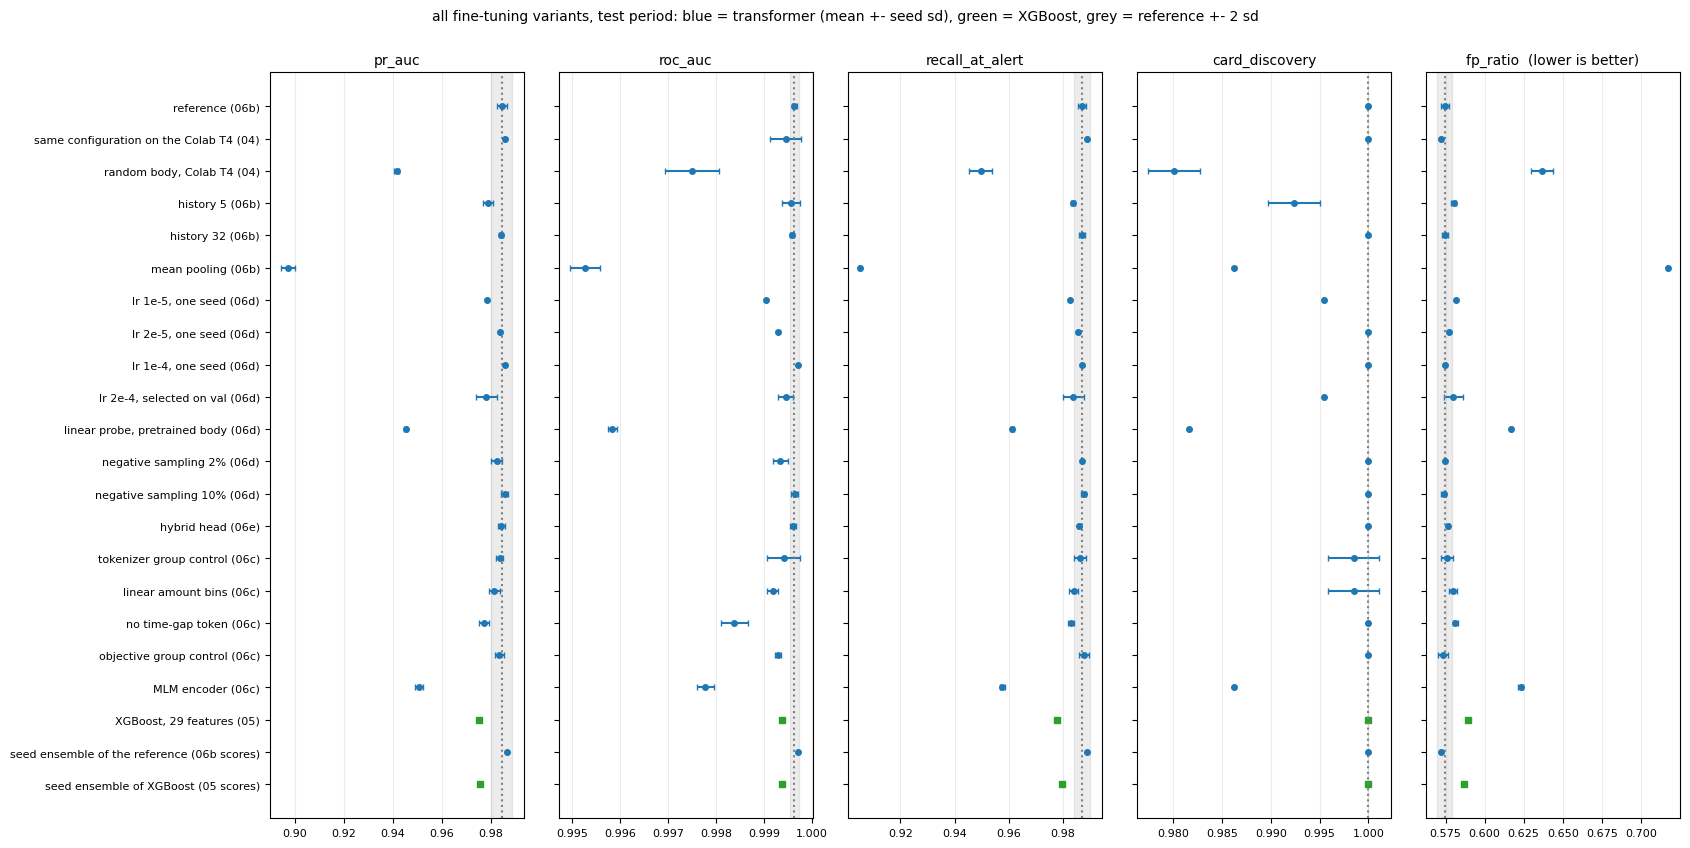

In [3]:
import matplotlib.pyplot as plt
plot = [r for r in rows if not (r["variant"].startswith("history 0") or "random body (06d)" in r["variant"] or "current row only" in r["variant"])]   # three far-left rows would flatten every axis
plot = plot[::-1]; y = np.arange(len(plot)); names = [r["variant"] for r in plot]
fig, axes = plt.subplots(1, len(METRICS), figsize=(17, 0.32 * len(plot) + 1.4), sharey=True)
for ax, k in zip(axes, METRICS):
    mean = np.array([r["metrics"][k]["mean"] for r in plot]); sd = np.array([r["metrics"][k]["sd"] if r["sd"] is not None else 0 for r in plot])
    xg = np.array(["XGBoost" in r["variant"] for r in plot])
    ax.errorbar(mean[~xg], y[~xg], xerr=sd[~xg], fmt="o", color="tab:blue", ecolor="tab:blue", capsize=2, ms=4)
    ax.plot(mean[xg], y[xg], "s", color="tab:green", ms=5)
    rm, rs = ref["metrics"][k]["mean"], ref["metrics"][k]["sd"]
    ax.axvline(rm, color="grey", ls=":"); ax.axvspan(rm - 2 * rs, rm + 2 * rs, color="grey", alpha=0.15)
    ax.set_title(k + ("  (lower is better)" if k == "fp_ratio" else ""), fontsize=10); ax.grid(axis="x", alpha=0.25); ax.tick_params(axis="x", labelsize=8)
axes[0].set_yticks(y); axes[0].set_yticklabels(names, fontsize=8)
fig.suptitle("all fine-tuning variants, test period: blue = transformer (mean +- seed sd), green = XGBoost, grey = reference +- 2 sd", fontsize=10, y=1.0)
fig.tight_layout(); fig.savefig(f"{RES}/06f_compare.png", dpi=120, bbox_inches="tight"); plt.show()

## Stage 6f-2: PR curves on the test period, seed 0 of each variant

The curves are drawn from the saved test scores, so the T4 runs appear too (as curves, they are informative; their sd units still are not comparable). Right panel: the part that decides PR-AUC here, recall above 0.8.

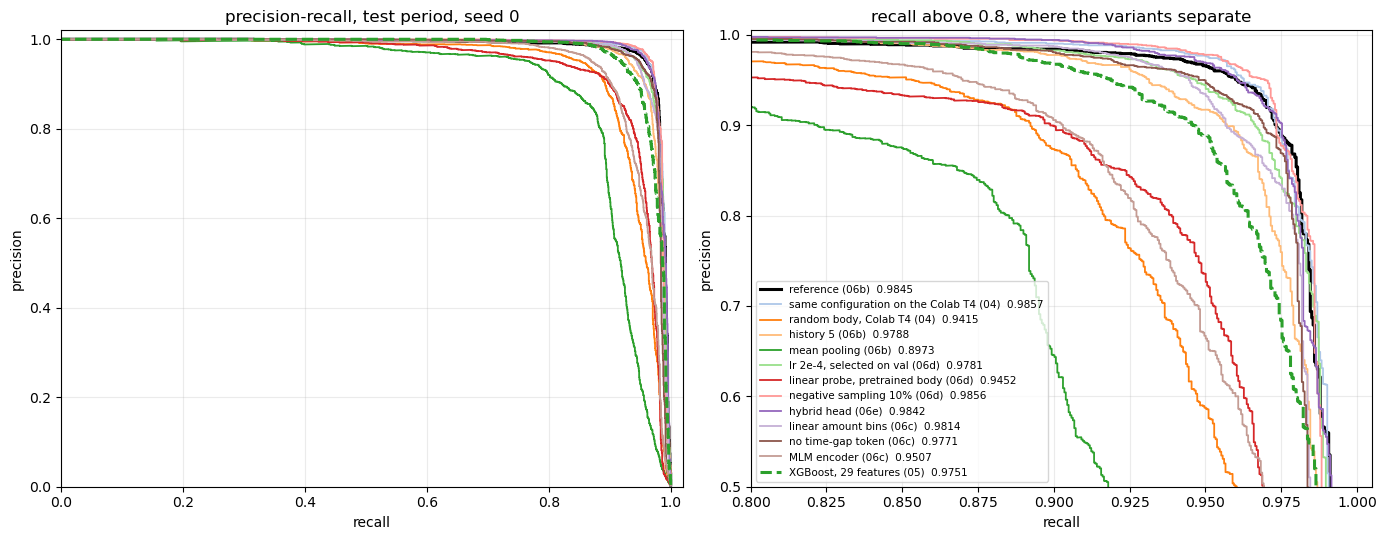

In [4]:
from sklearn.metrics import precision_recall_curve
CURVES = ["reference (06b)", "same configuration on the Colab T4 (04)", "random body, Colab T4 (04)", "history 5 (06b)", "mean pooling (06b)",
          "lr 2e-4, selected on val (06d)", "linear probe, pretrained body (06d)", "negative sampling 10% (06d)", "hybrid head (06e)",
          "linear amount bins (06c)", "no time-gap token (06c)", "MLM encoder (06c)", "XGBoost, 29 features (05)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cmap = plt.get_cmap("tab20")
for i, name in enumerate(CURVES):
    r = next((r for r in rows if r["variant"] == name), None)
    if r is None or not r["dir"]: continue
    sc = seed_scores(r["dir"], seeds=(0,))
    if not sc: print("no scores for", name); continue
    p, rc, _ = precision_recall_curve(yt, sc[0])
    style = dict(color="black", lw=2.2) if name.startswith("reference") else dict(color="tab:green", lw=2.2, ls="--") if "XGBoost" in name else dict(color=cmap(i), lw=1.3)
    for ax in axes: ax.plot(rc, p, label=f"{name}  {r['metrics']['pr_auc']['mean']:.4f}", **style)
axes[0].set_xlim(0, 1.02); axes[0].set_ylim(0, 1.02); axes[0].set_title("precision-recall, test period, seed 0")
axes[1].set_xlim(0.8, 1.005); axes[1].set_ylim(0.5, 1.005); axes[1].set_title("recall above 0.8, where the variants separate")
for ax in axes: ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.grid(alpha=0.25)
axes[1].legend(fontsize=7.5, loc="lower left"); fig.tight_layout(); fig.savefig(f"{RES}/06f_compare_pr.png", dpi=120); plt.show()

## Stage 6f-3: loss and validation PR-AUC during fine-tuning, seed 0 of each transformer variant

From each run's `trainer_state.json`: train loss every 50 steps (the sampled training set, so levels are only comparable between runs with the same sampling rate), validation loss and PR-AUC every 500 steps. XGBoost logs no step curve (step 5 kept only its best iteration), so it has no line here.

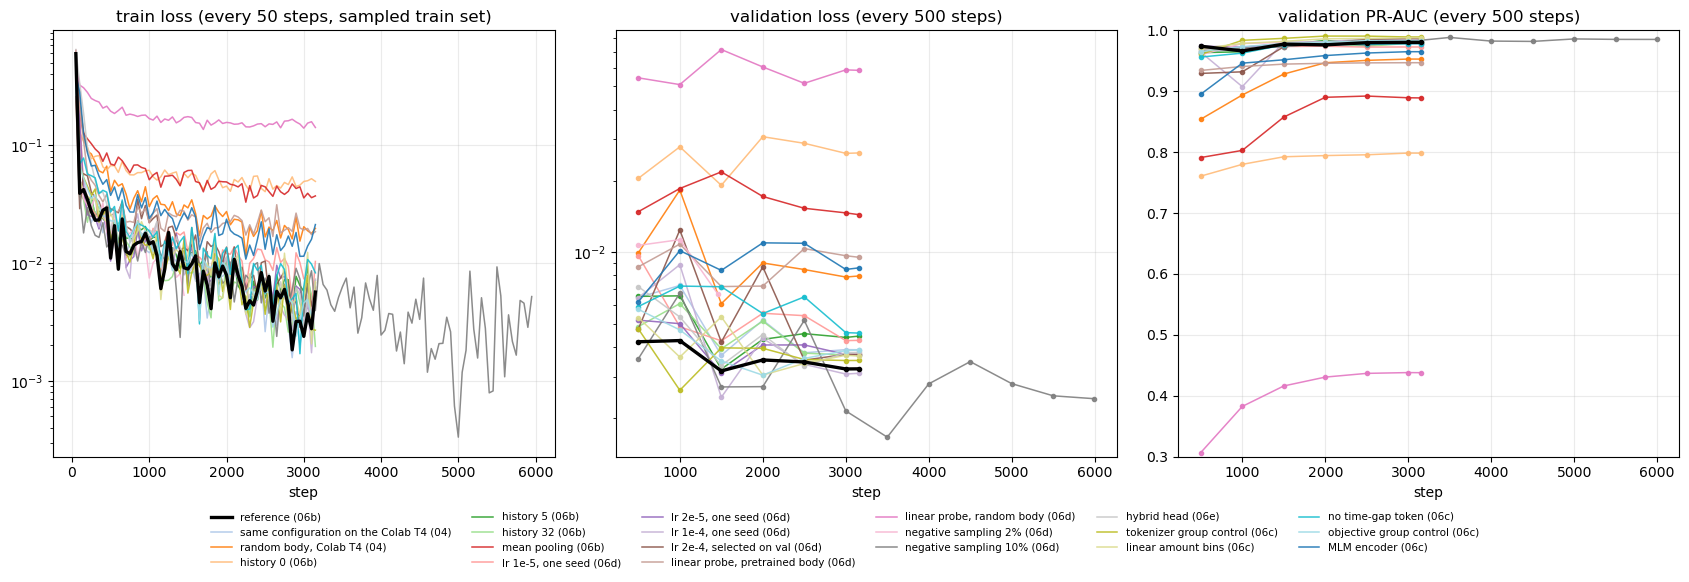

21 training logs read
saved 06f_compare_finetunes.json with 25 rows and 21 loss curves


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
curves = {}
for i, r in enumerate(rows):
    if not r["dir"] or "XGBoost" in r["variant"]: continue
    h = log_history(f"{ROOT}/{r['dir'].format(k=0)}")
    if h is None or not h["eval"]: continue
    curves[r["variant"]] = h
cmap = plt.get_cmap("tab20")
for i, (name, h) in enumerate(curves.items()):
    style = dict(color="black", lw=2.4, zorder=5) if name.startswith("reference") else dict(color=cmap(i % 20), lw=1.1, alpha=0.9)
    s, l = zip(*h["train"]); axes[0].plot(s, l, label=name, **style)
    s, vl, va = zip(*h["eval"]); axes[1].plot(s, vl, marker=".", **style); axes[2].plot(s, va, marker=".", **style)
axes[0].set_yscale("log"); axes[0].set_title("train loss (every 50 steps, sampled train set)"); axes[0].set_xlabel("step")
axes[1].set_yscale("log"); axes[1].set_title("validation loss (every 500 steps)"); axes[1].set_xlabel("step")
axes[2].set_title("validation PR-AUC (every 500 steps)"); axes[2].set_xlabel("step"); axes[2].set_ylim(0.3, 1.0)
for ax in axes: ax.grid(alpha=0.25)
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=7.5, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.12), frameon=False)
fig.tight_layout(); fig.savefig(f"{RES}/06f_compare_loss.png", dpi=120, bbox_inches="tight"); plt.show()
print(f"{len(curves)} training logs read")

out = {"reference": ref, "rows": rows, "n_variants_known": len(VARIANTS), "metrics": METRICS, "params": PARAMS,
       "loss_curves_seed0": {k: v for k, v in curves.items()}, "runtime": describe()}
json.dump(out, open(f"{RES}/06f_compare_finetunes.json", "w"), indent=1, default=float)
print("saved 06f_compare_finetunes.json with", len(rows), "rows and", len(curves), "loss curves")

## Stage 6f-4: paired bootstrap against XGBoost, for the reference and for the validation-selected learning rate

06a's bootstrap interval belongs to one model: the reference, fine-tuned at the learning rate fixed before any sweep (5e-5). 06d then showed that strict selection on the validation month picks 2e-4, which tests 3 sd lower, and that the decision to keep 5e-5 was taken with the test numbers in view. The interval for the validation-selected model therefore has to be measured as well, not inferred from the reference's width. Same procedure as 06a: 1,000 card resamples, transformer seed k against XGBoost seed k, three metrics. The 04 pair reproduces 06a's numbers as a check; the pairs run in parallel processes.

In [6]:
import time, multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from tfm.validate import bootstrap_diff

BOOT_PAIRS = [("06a pair: 04 pretrained H12 on the T4, seed 0", "finetune/pretrained_H12/seed{k}", (0,)),
              ("reference, lr 5e-5 fixed in advance (06b)", "ablate/H12_last/seed{k}", (0, 1, 2)),
              ("lr 2e-4, selected on validation (06d)", "extras/lr_2e-04/seed{k}", (0, 1, 2))]
xgb = seed_scores("baseline/full/seed{k}")
jobs = []
for label, pat, seeds in BOOT_PAIRS:
    for k in seeds:
        s = seed_scores(pat, (k,))
        if s and len(xgb) > k: jobs.append((label, k, s[0], xgb[k]))
        else: print("skipped, scores missing:", label, k)
t0 = time.time()
with ProcessPoolExecutor(max_workers=min(len(jobs), 8), mp_context=mp.get_context("spawn")) as ex:
    res = list(ex.map(bootstrap_diff, [yt] * len(jobs), [j[2] for j in jobs], [j[3] for j in jobs], [ct] * len(jobs)))
print(f"{len(jobs)} paired bootstraps, 1,000 card resamples each, {time.time() - t0:.0f} s wall in parallel")

boots = []
for (label, k, _, _), b in zip(jobs, res):
    row = {"variant": label, "seed": k}
    for m in ("pr_auc", "recall_at_alert", "fp_ratio"):
        row[m] = {"diff": b[m]["diff"], "ci_low": b[m]["ci_low"], "ci_high": b[m]["ci_high"], "n_boot": b[m]["n_boot"]}
    row["pr_auc_excludes_zero"] = bool(b["pr_auc"]["ci_low"] > 0 or b["pr_auc"]["ci_high"] < 0)
    boots.append(row)
bt = pd.DataFrame([{"variant": r["variant"], "seed": r["seed"],
                    **{f"{m} {q}": r[m][q] for m in ("pr_auc", "recall_at_alert", "fp_ratio") for q in ("diff", "ci_low", "ci_high")},
                    "PR-AUC CI excludes 0": r["pr_auc_excludes_zero"]} for r in boots])
display(bt.style.format("{:+.4f}", subset=[c for c in bt if c not in ("variant", "seed", "PR-AUC CI excludes 0")]).hide(axis="index"))
out["bootstrap_vs_xgboost"] = boots
json.dump(out, open(f"{RES}/06f_compare_finetunes.json", "w"), indent=1, default=float)
print("06f_compare_finetunes.json updated with bootstrap_vs_xgboost,", len(boots), "pairs")

7 paired bootstraps, 1,000 card resamples each, 793 s wall in parallel


variant,seed,pr_auc diff,pr_auc ci_low,pr_auc ci_high,recall_at_alert diff,recall_at_alert ci_low,recall_at_alert ci_high,fp_ratio diff,fp_ratio ci_low,fp_ratio ci_high,PR-AUC CI excludes 0
"06a pair: 04 pretrained H12 on the T4, seed 0",0,+0.0106,+0.0059,+0.0156,+0.0103,+0.0039,+0.0163,-0.0165,-0.0265,-0.0065,True
"reference, lr 5e-5 fixed in advance (06b)",0,+0.0083,+0.0032,+0.0135,+0.0084,+0.0014,+0.0155,-0.0135,-0.0249,-0.0023,True
"reference, lr 5e-5 fixed in advance (06b)",1,+0.0075,+0.0020,+0.0130,+0.0093,+0.0009,+0.0160,-0.0150,-0.0252,-0.0013,True
"reference, lr 5e-5 fixed in advance (06b)",2,+0.0122,+0.0072,+0.0176,+0.0098,+0.0035,+0.0165,-0.0157,-0.0261,-0.0059,True
"lr 2e-4, selected on validation (06d)",0,+0.0075,+0.0030,+0.0120,+0.0098,+0.0026,+0.0156,-0.0157,-0.0250,-0.0046,True
"lr 2e-4, selected on validation (06d)",1,-0.0009,-0.0066,+0.0038,+0.0037,-0.0053,+0.0101,-0.0061,-0.0162,+0.0091,False
"lr 2e-4, selected on validation (06d)",2,+0.0024,-0.0035,+0.0077,+0.0042,-0.0029,+0.0109,-0.0068,-0.0171,+0.0050,False


06f_compare_finetunes.json updated with bootstrap_vs_xgboost, 7 pairs


## Stage 6f-5: agreement table between the transformer and XGBoost, and an exact McNemar test

06a listed the frauds flagged by only one model but kept just the 20 with the largest score gap per side (`disagreements(k=20)`), so the list length is not the count. This stage counts the full 2 x 2 table over all test frauds for the 06a pair (04 pretrained H12 on the T4, seed 0, against XGBoost seed 0, both at the 0.6% alert rate): both flag, transformer only, XGBoost only, neither. The two off-diagonal cells feed an exact two-sided McNemar test: under equal performance each discordant fraud is equally likely to go either way. The test treats the discordant frauds as independent, which frauds inside one burst are not, so its p-value is optimistic; the card-level bootstrap of 6f-4 stays the primary evidence and the table is a description of where the two models differ.

In [7]:
from tfm.validate import agreement_table, mcnemar_exact
tra = seed_scores("finetune/pretrained_H12/seed{k}", (0,))
xgb0 = seed_scores("baseline/full/seed{k}", (0,))
if tra and xgb0:
    agree = agreement_table(yt, tra[0], xgb0[0], alert_rate=0.006)
    agree["n_fraud"] = int(sum(v for k, v in agree.items() if k != "n_fraud"))
    agree["mcnemar_exact_p"] = mcnemar_exact(agree["only_a"], agree["only_b"])
    agree["pair"] = "04 pretrained H12 on the T4, seed 0 (A) vs XGBoost 29 features, seed 0 (B), alert rate 0.6%"
    display(pd.DataFrame([[agree["both"], agree["only_a"]], [agree["only_b"], agree["neither"]]],
                         index=["transformer flags", "transformer misses"], columns=["XGBoost flags", "XGBoost misses"]))
    print(f"{agree['n_fraud']} test frauds; agree on {agree['both'] + agree['neither']}, disagree on {agree['only_a'] + agree['only_b']} "
          f"({agree['only_a']} transformer only, {agree['only_b']} XGBoost only); exact McNemar p = {agree['mcnemar_exact_p']:.2g}")
    out["agreement"] = agree
    json.dump(out, open(f"{RES}/06f_compare_finetunes.json", "w"), indent=1, default=float)
    print("06f_compare_finetunes.json updated with agreement")
else:
    print("skipped, scores missing")

,XGBoost flags,XGBoost misses
transformer flags,2090,30
transformer misses,8,17


2145 test frauds; agree on 2107, disagree on 38 (30 transformer only, 8 XGBoost only); exact McNemar p = 0.00047
06f_compare_finetunes.json updated with agreement


## What to read off the table and the figures

- Parameter cells in yellow are the one thing each row changed. Rows at or inside the grey band are ties with the reference; outside it, the change mattered. Single-seed learning-rate rows show a trend only.
- The five metric panels should agree; where they do not (a variant that ties on PR-AUC but loses on FP ratio, say) the table is more informative than the headline number.
- The two ensemble rows answer the fairness question: if averaging seeds lifts the transformer and the tree by the same amount, the gap between them is unchanged; if it lifts only one, the headline comparison in the report must use both ensembles or neither.
- PR curves: every variant is at precision 1 up to recall 0.8; the ranking is decided in the last fifth of recall, which is why ROC-AUC shows nothing.
- Loss curves: a variant whose validation PR-AUC is still rising at the last step was under-trained at 3 epochs; one whose validation loss rises while PR-AUC holds is over-confident, not wrong (06d's calibration).
- The T4 and XGBoost rows carry a difference but no sd units on purpose; see the rules above.
- The bootstrap table has one interval per seed pair. The validation-selected learning rate is the row the report's range (0.003 to 0.011 over XGBoost) has to be checked against: if its intervals include zero, the bottom of the range is a tie, and the sentence in the report must say so.

- The agreement table is the one place the two models are compared fraud by fraud. Its diagonal (both, neither) says nothing about which is better; the recall gap is the difference of the two off-diagonal cells, and the McNemar p says whether that split could be even by chance, before accounting for bursts.


## Push results and this notebook back to GitHub

In [8]:
import shutil, glob, os, json
os.makedirs("results/metrics", exist_ok=True); os.makedirs("results/figures", exist_ok=True)
for f in glob.glob(f"{ROOT}/results/*.json"):
    shutil.copy(f, "results/metrics/")
for f in glob.glob(f"{ROOT}/results/*.png"):
    shutil.copy(f, "results/figures/")
if on_colab():
    def same_code(a, b):   # a Drive notebook may be copied back only if its code cells equal the repo version
        cells = lambda p: ["".join(c["source"]) for c in json.load(open(p))["cells"] if c["cell_type"] == "code"]
        return cells(a) == cells(b)
    for f in glob.glob(f"{ROOT}/notebooks/*.ipynb"):   # outputs are kept so GitHub shows them
        repo = f"notebooks/{os.path.basename(f)}"
        if not os.path.exists(repo) or same_code(f, repo):
            shutil.copy(f, repo)
        else:
            print("STALE, not copied:", os.path.basename(f), "-> delete it from Drive and rerun the setup cell")
    try: name, email = userdata.get("GIT_NAME"), userdata.get("GIT_EMAIL")   # commit identity from Colab secrets, never from the notebook
    except Exception: name = email = ""
    if name and email and tok:
        !git config user.name "{name}" && git config user.email "{email}"
        !git add results notebooks && git commit -q -m "results and notebooks from Colab" && git pull --rebase -q && git push -q   # another notebook may have pushed meanwhile; the files are disjoint
        !git log --oneline | head -1
    else:
        print("not committed: set GIT_NAME, GIT_EMAIL and GH_TOKEN (Contents: read and write on your repo) in Colab secrets to push from Colab")
else:
    print("laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal")
    !git status --short results notebooks

laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal


 M notebooks/06f_compare_finetunes.ipynb
 M notebooks/README.md
 M results/metrics/06f_compare_finetunes.json


In [9]:
if on_colab():
    drive.flush_and_unmount()